CHARGEMENT DES PACKAGES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv("../data/PS_20174392719_1491204439457_log.csv")
print(df.shape)
df.head()

(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


STRUCTURES ET VALEURS MANQUANTES

In [5]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

DESEQUILIBRE

In [3]:
counts = df["isFraud"].value_counts()
print(counts)
print(f"Taux de fraude : {df["isFraud"].mean():.4%}")

isFraud
0    6354407
1       8213
Name: count, dtype: int64
Taux de fraude : 0.1291%


TYPE DE TRANSACTION

In [4]:
print(df["type"].value_counts())
print(df.groupby("type")["isFraud"].agg(["sum","mean"]))

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64
           sum      mean
type                    
CASH_IN      0  0.000000
CASH_OUT  4116  0.001840
DEBIT        0  0.000000
PAYMENT      0  0.000000
TRANSFER  4097  0.007688


RESTREINDRE AUX TYPES A RISQUE

In [6]:
data = df[df["type"].isin(["TRANSFER","CASH_OUT"])].copy()
print(data.shape,f"{data["isFraud"].mean():.4%}")

(2770409, 11) 0.2965%


MONTANTS FRAUDULEUX ET MONTANTS NORMAL

In [7]:
print(data.groupby("isFraud")["amount"].describe())

             count          mean           std   min          25%        50%  \
isFraud                                                                        
0        2762196.0  3.141155e+05  8.771441e+05  0.01   82908.2325  171034.46   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.3300  441423.44   

                 75%          max  
isFraud                            
0         305994.185  92445516.64  
1        1517771.480  10000000.00  


SIGNAL DES SOLDES

In [14]:
data["errorOrig"] = data["oldbalanceOrg"]-data["amount"]-data["newbalanceOrig"]

data["origEmptied"] = ((data["newbalanceOrig"]==0) & (data["oldbalanceOrg"]>0)).astype(int)
print(data["origEmptied"].sum())

print(data.groupby("isFraud")[["errorOrig","origEmptied"]].mean())

1188074
             errorOrig  origEmptied
isFraud                            
0       -286803.509954     0.427219
1        -10692.325265     0.975527


HISTORIQUE PAR CLIENT

In [15]:
print (data["nameOrig"].nunique(),"expediteurs unique sur",len(data),"lignes")
print(data["nameOrig"].value_counts().head())

2768630 expediteurs unique sur 2770409 lignes
nameOrig
C2098525306    3
C1902386530    3
C724452879     3
C1101598632    2
C35005848      2
Name: count, dtype: int64


In [10]:
fr = data[data["isFraud"] == 1]
print(fr[["oldbalanceOrg", "amount", "newbalanceOrig"]].head(10))
print((data["newbalanceOrig"] == 0).groupby(data["isFraud"]).mean())
print(data["origEmptied"].sum())

      oldbalanceOrg      amount  newbalanceOrig
2            181.00      181.00             0.0
3            181.00      181.00             0.0
251         2806.00     2806.00             0.0
252         2806.00     2806.00             0.0
680        20128.00    20128.00             0.0
681        20128.00    20128.00             0.0
724            0.00   416001.33             0.0
969      1277212.77  1277212.77             0.0
970      1277212.77  1277212.77             0.0
1115       35063.63    35063.63             0.0
isFraud
0    0.900951
1    0.980519
Name: newbalanceOrig, dtype: float64
0


In [11]:
# Destinataires : un même compte reçoit-il plusieurs transactions ?
dest_counts = data["nameDest"].value_counts()
print(dest_counts.head())
data["destFreq"] = data["nameDest"].map(dest_counts)
print(data.groupby("isFraud")["destFreq"].describe())

# Heure de la journée (step = 1 heure simulée)
data["hour"] = data["step"] % 24
print(data.groupby("hour")["isFraud"].mean().round(4))

nameDest
C1286084959    75
C665576141     68
C1360767589    68
C97730845      67
C248609774     64
Name: count, dtype: int64
             count       mean       std  min  25%  50%   75%   max
isFraud                                                           
0        2762196.0  11.599926  8.665446  1.0  5.0  9.0  16.0  75.0
1           8213.0   5.699623  6.832186  1.0  1.0  3.0   8.0  56.0
hour
0     0.0165
1     0.0596
2     0.1935
3     0.4179
4     0.5352
5     0.5791
6     0.3960
7     0.1290
8     0.0357
9     0.0028
10    0.0020
11    0.0016
12    0.0016
13    0.0016
14    0.0018
15    0.0018
16    0.0017
17    0.0017
18    0.0013
19    0.0011
20    0.0014
21    0.0038
22    0.0057
23    0.0085
Name: isFraud, dtype: float64


caracteristiques et separation des données

In [16]:
# Tri chronologique : indispensable pour le split et pour les features "passées"
data = data.sort_values("step").reset_index(drop=True)

# Features
data["isTransfer"] = (data["type"] == "TRANSFER").astype(int)
data["errorDest"] = data["oldbalanceDest"] + data["amount"] - data["newbalanceDest"]
data["hour"] = data["step"] % 24
# Nb de transactions déjà reçues par ce destinataire AVANT celle-ci (pas de fuite)
data["destPrior"] = data.groupby("nameDest").cumcount()

features = ["isTransfer", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest", "errorOrig", "errorDest",
            "origEmptied", "hour", "destPrior"]

# Split temporel : on entraîne sur le passé, on teste sur le futur
cut = data["step"].quantile(0.8)
train = data[data["step"] <= cut]
test  = data[data["step"] >  cut]

X_train, y_train = train[features], train["isFraud"]
X_test,  y_test  = test[features],  test["isFraud"]

print(f"cut = step {cut:.0f}")
print("train :", X_train.shape, y_train.sum(), "fraudes", f"({y_train.mean():.4%})")
print("test  :", X_test.shape,  y_test.sum(),  "fraudes", f"({y_test.mean():.4%})")

cut = step 354
train : (2217905, 11) 3955 fraudes (0.1783%)
test  : (552504, 11) 4258 fraudes (0.7707%)


trois figures pour le rapport

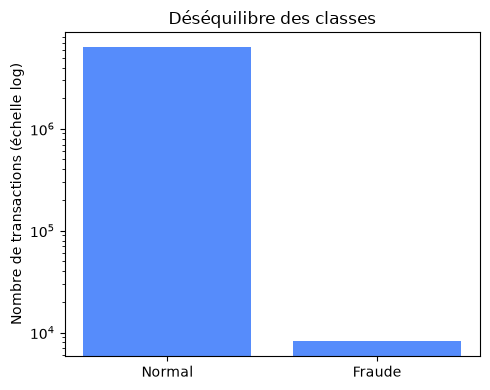

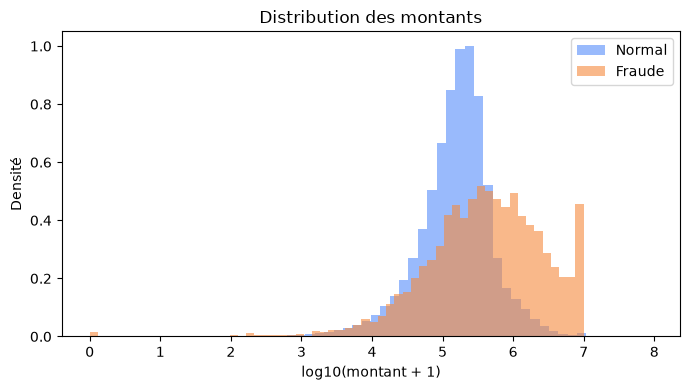

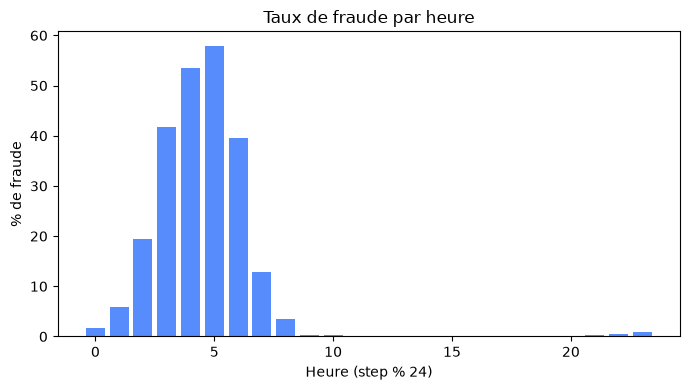

In [17]:
import os
os.makedirs("../figures", exist_ok=True)

# Fig 1 : déséquilibre (échelle log pour voir les fraudes)
fig, ax = plt.subplots(figsize=(5, 4))
counts = df["isFraud"].value_counts()
ax.bar(["Normal", "Fraude"], counts.values)
ax.set_yscale("log")
ax.set_ylabel("Nombre de transactions (échelle log)")
ax.set_title("Déséquilibre des classes")
plt.tight_layout(); plt.savefig("../figures/01_desequilibre.png", dpi=150); plt.show()

# Fig 2 : montants fraude vs normal (log)
fig, ax = plt.subplots(figsize=(7, 4))
for label, g in data.groupby("isFraud"):
    ax.hist(np.log10(g["amount"] + 1), bins=60, alpha=0.6, density=True,
            label="Fraude" if label else "Normal")
ax.set_xlabel("log10(montant + 1)"); ax.set_ylabel("Densité")
ax.set_title("Distribution des montants"); ax.legend()
plt.tight_layout(); plt.savefig("../figures/02_montants.png", dpi=150); plt.show()

# Fig 3 : taux de fraude par heure
rate = data.groupby("hour")["isFraud"].mean() * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rate.index, rate.values)
ax.set_xlabel("Heure (step % 24)"); ax.set_ylabel("% de fraude")
ax.set_title("Taux de fraude par heure")
plt.tight_layout(); plt.savefig("../figures/03_heure.png", dpi=150); plt.show()